## Representación One-Hot Encoding

Podemos representar cada palabra mediante un vector **One-Hot**. Primero construimos un vocabulario y asignamos una posición a cada palabra. Después, cada palabra se representa con un vector de ceros y un único `1` en la posición correspondiente.

Para un vocabulario $\mathbf
{V} = \{w_1, w_2, \dots, w_N\}$, la palabra $w_i$ se codifica como:

$$\mathbf{e}(w_i) = [0, \dots, 0, 1, 0, \dots, 0] \in \mathbb{R}^{N}$$

One-Hot indica **identidad**, pero no frecuencia ni significado: dos palabras diferentes tienen vectores ortogonales y todos los vectores tienen la misma longitud.

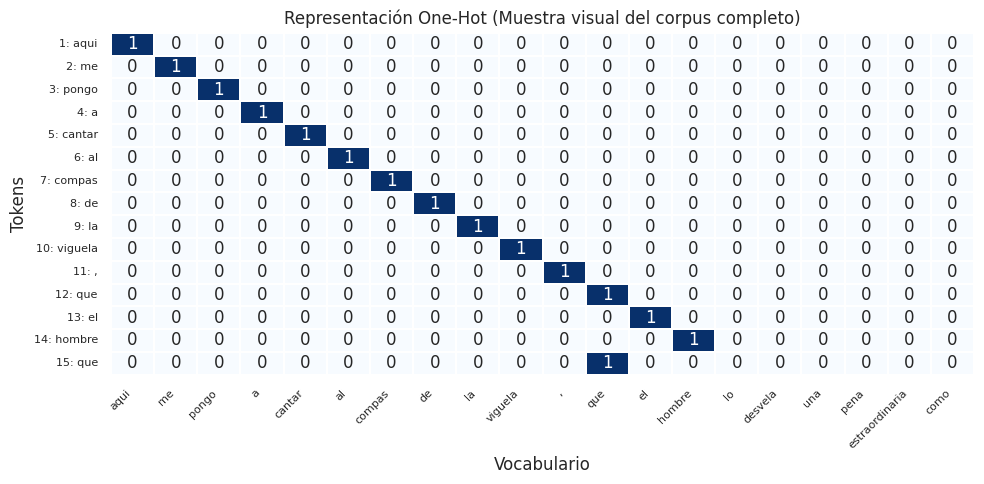

### 💡 Aclaración sobre las palabras repetidas en el eje de la matriz One-Hot

Si observas el eje vertical (Y) del mapa de calor anterior, notarás que la palabra **"que"** aparece repetida (por ejemplo, en la fila 12 y la fila 15).

**¿Por qué sucede esto si el vocabulario no debe tener duplicados?**

* **El eje vertical (Y) representa los Tokens de la frase procesada:** Es la secuencia real del texto en orden cronológico. Como en una misma estrofa o frase podemos repetir palabras (por ejemplo, *"...**que** el hombre **que** lo desvela..."*), estas palabras deben aparecer en sus respectivas posiciones secuenciales para mantener la estructura del texto.
* **El eje horizontal (X) representa el Vocabulario único:** Aquí cada columna corresponde a un índice único y exclusivo del diccionario global. No hay repetidos.

Por ende, la fila 12 y la fila 15 activan su `1` exactamente en la misma columna (la columna de la palabra **"que"**), demostrando que vectores One-Hot idénticos representan la misma identidad de palabra en diferentes momentos del tiempo.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import random
import requests
import unicodedata

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from collections import defaultdict, Counter
from typing import Callable, Iterable

In [ ]:
class Corpus():
  def __init__(self, documents):
    self.raw_documents = documents

  def get_raw_documents(self):
    return self.raw_documents

  def sample(self, lenght=3):
    for i in range(min(lenght, len(self.raw_documents))):
      print(f'\n ==== Document {i+1} ==== \n\n{self.raw_documents[i][:250]}')

In [ ]:
class DocumentsCleaner():

    @staticmethod
    def _transform(
        documents: Iterable[str],
        function: Callable[[str], str],
        *,
        discard_empty: bool = False
    ) -> list[str]:
        """Aplica una transformación y devuelve una nueva lista."""
        result = [function(document) for document in documents]
        return [doc for doc in result if doc] if discard_empty else result

    def delete_init_final_chars(self, documents):
        """Elimina espacios al inicio y al final y descarta documentos vacíos."""
        return self._transform(
            documents, str.strip, discard_empty=True
        )

    def to_lower_case(self, documents):
        """Convierte los documentos a minúsculas."""
        return self._transform(documents, str.lower)

    def delete_accents(self, documents):
        """Elimina los diacríticos de los documentos."""
        def remove_accents(document):
            return ''.join(
                char
                for char in unicodedata.normalize('NFD', document)
                if unicodedata.category(char) != 'Mn'
            )

        return self._transform(documents, remove_accents)

    def conserve_letters_numbers_spaces_and_signs(self, documents):
        """Conserva los caracteres permitidos."""
        pattern = re.compile(r'[^a-zñ0-9\s.,;:¿?¡!"“”\'()\-—…]')

        return self._transform(
            documents,
            lambda document: pattern.sub('', document)
        )

    def normalize_multiple_spaces(self, documents):
        """Reduce los espacios consecutivos a uno solo."""
        return self._transform(
            documents,
            lambda document: re.sub(r'\s+', ' ', document).strip()
        )

    def conserve_documents_with_than_words(self, documents, n=5):
        """Conserva documentos con más de n palabras."""
        return [
            document
            for document in documents
            if document and len(document.split()) > n
        ]

    def apply_rgx(self, documents, rgx):
        """Descarta documentos que coinciden con el patrón
        o que tienen menos de dos líneas.
        """
        pattern = re.compile(rgx)

        return [
            document
            for document in documents
            if not pattern.match(document)
            and len(document.split('\n')) >= 2
        ]

In [ ]:
class Tokenizer():

  def tokenize(self, documents):
    """
    Separa palabras, números y signos de puntuación
    """
    tokenized_documents = []

    for i, doc in enumerate(documents):
        tokens = re.findall(r'\w+|[^\w\s]', doc, flags=re.UNICODE)
        tokenized_documents.append(tokens)

    self.tokens = tokenized_documents

  def get_tokens(self):
    return self.tokens

  def sample(self, lenght=3):
    for i in range(min(lenght, len(self.tokens))):
      print(f'\n ==== Document {i+1} ==== \n\n{self.tokens[i][:250]}')

In [ ]:
class OneHot():

  def __init__(self, documents):
        self.all_tokens_sequence = tuple(
            token
            for document in documents
            for token in document
        )

        self.one_hot_vocab = tuple(
            dict.fromkeys(self.all_tokens_sequence)
        )

        self.vocab_to_index = {
            token: i
            for i, token in enumerate(self.one_hot_vocab)
        }

        # Una fila por token, una columna por categoría.
        rows = np.arange(len(self.all_tokens_sequence))
        cols = np.array([
            self.vocab_to_index[token]
            for token in self.all_tokens_sequence
        ])

        self.one_hot_matrix = np.zeros(
            (len(rows), len(self.one_hot_vocab)),
            dtype=np.int8
        )
        self.one_hot_matrix[rows, cols] = 1

  def map_vocab_to_index(self):
      return self.vocab_to_index.copy()

  def get_word_vector(self, word):
      index = self.vocab_to_index.get(word)

      if index is None:
          raise ValueError(f"El token {word!r} no está en el vocabulario.")

      vector = np.zeros(len(self.one_hot_vocab), dtype=np.int8)
      vector[index] = 1
      return vector

  def to_pandas_df(self):
      return pd.DataFrame(
          self.one_hot_matrix.copy(),
          index=[
              f"{i + 1}: {token}"
              for i, token in enumerate(self.all_tokens_sequence)
          ],
          columns=self.one_hot_vocab
      )

In [ ]:
# Paso 1 - Cargar, generar u obtener nuestro corpus (El universo de Documentos), como estamos trabajando con solo el Martin Fierro, nuestro corpus será cada una de las estrofas,
# que vamos a llamar documentos.

# URL del archivo JSON con las estrofas
url_json = 'https://raw.githubusercontent.com/Lautauro/fierrodiario/refs/heads/pages/json/estrofas.json'

print(f"Cargando datos desde {url_json}...")
response = requests.get(url_json)
response.raise_for_gradual_behavior = True # Asegura que la descarga sea correcta
data_json = response.json()

# Vamos a extraer los textos de las estrofas
raw_stanzas = []
if isinstance(data_json, dict) and 'estrofas' in data_json:
    # Si es un diccionario con la key 'estrofas'
    raw_stanzas = [item.get('texto', '') if isinstance(item, dict) else str(item) for item in data_json['estrofas']]
elif isinstance(data_json, list):
    # Si es una lista directamente
    raw_stanzas = [item.get('texto', '') if isinstance(item, dict) else str(item) for item in data_json]


corpus = Corpus(raw_stanzas)

corpus.sample(lenght=5)

Cargando datos desde https://raw.githubusercontent.com/Lautauro/fierrodiario/refs/heads/pages/json/estrofas.json...

 ==== Document 1 ==== 

Aquí me pongo á cantar
Al compás de la vigüela,
Que el hombre que lo desvela
Una pena estraordinaria,
Como la ave solitaria
Con el cantar se consuela.

 ==== Document 2 ==== 

Pido á los Santos del Cielo
Que ayuden mi pensamiento,
Les pido en este momento
Que voy á cantar mi historia
Me refresquen la memoria
Y aclaren mi entendimiento.

 ==== Document 3 ==== 

Vengan Santos milagrosos,
Vengan todos en mi ayuda,
Que la lengua se me añuda
Y se me turba la vista;
Pido á mi Dios que me asista
En una ocasión tan ruda.

 ==== Document 4 ==== 

Yo he visto muchos cantores,
Con famas bien otenidas,
Y que despues de adquiridas
No las quieren sustentar:
Parece que sin largar
Se cansaron en partidas.

 ==== Document 5 ==== 

Mas ande otro criollo pasa
Martin Fierro ha de pasar,
Nada lo hace recular
Ni las fantasmas lo espantan;
Y dende que todos cantan
Yo ta

In [ ]:
# Paso 2 - Limpieza de nuestro corpus

raw_documents = corpus.get_raw_documents()

cleaner = DocumentsCleaner()

cleaned_documents = cleaner.delete_init_final_chars(raw_documents)
cleaned_documents = cleaner.to_lower_case(cleaned_documents)
cleaned_documents = cleaner.delete_accents(cleaned_documents)
cleaned_documents = cleaner.normalize_multiple_spaces(cleaned_documents)

total_documents = len(cleaned_documents)

print(f'Total de documentos limpiados: {total_documents}')
print("Documentos únicos:", len(set(cleaned_documents)))
print('\nEjemplos:')
for i in range(min(3, total_documents)):
    print(f'\nDocumento {i+1}: {cleaned_documents[i][:250]}')

Total de documentos limpiados: 398
Documentos únicos: 398

Ejemplos:

Documento 1: aqui me pongo a cantar al compas de la viguela, que el hombre que lo desvela una pena estraordinaria, como la ave solitaria con el cantar se consuela.

Documento 2: pido a los santos del cielo que ayuden mi pensamiento, les pido en este momento que voy a cantar mi historia me refresquen la memoria y aclaren mi entendimiento.

Documento 3: vengan santos milagrosos, vengan todos en mi ayuda, que la lengua se me anuda y se me turba la vista; pido a mi dios que me asista en una ocasion tan ruda.


In [ ]:
# Paso 3 - Tokenizar ej. aqui me pongo a cantar -> ['aqui', 'me', 'pongo', 'a', 'cantar']

tokenizer = Tokenizer()

tokenizer.tokenize(cleaned_documents)

tokenizer.sample(lenght=5)

tokenized_documents = tokenizer.get_tokens()

# Podemos notar, que en nuestros ejemplos hay tokens que se repiten, por ej la coma ','.
# ¿Por qué no conviene eliminar los duplicados ahora?
# Si conviertes cada documento en un set, perderás información importante:
#  Frecuencia: no sabrás cuántas veces aparece una palabra.
#  Orden: no podrás reconstruir los versos ni estudiar secuencias de palabras.
#  Contexto: dificultarás el entrenamiento de modelos de lenguaje, como los modelos de n-gramas.


 ==== Document 1 ==== 

['aqui', 'me', 'pongo', 'a', 'cantar', 'al', 'compas', 'de', 'la', 'viguela', ',', 'que', 'el', 'hombre', 'que', 'lo', 'desvela', 'una', 'pena', 'estraordinaria', ',', 'como', 'la', 'ave', 'solitaria', 'con', 'el', 'cantar', 'se', 'consuela', '.']

 ==== Document 2 ==== 

['pido', 'a', 'los', 'santos', 'del', 'cielo', 'que', 'ayuden', 'mi', 'pensamiento', ',', 'les', 'pido', 'en', 'este', 'momento', 'que', 'voy', 'a', 'cantar', 'mi', 'historia', 'me', 'refresquen', 'la', 'memoria', 'y', 'aclaren', 'mi', 'entendimiento', '.']

 ==== Document 3 ==== 

['vengan', 'santos', 'milagrosos', ',', 'vengan', 'todos', 'en', 'mi', 'ayuda', ',', 'que', 'la', 'lengua', 'se', 'me', 'anuda', 'y', 'se', 'me', 'turba', 'la', 'vista', ';', 'pido', 'a', 'mi', 'dios', 'que', 'me', 'asista', 'en', 'una', 'ocasion', 'tan', 'ruda', '.']

 ==== Document 4 ==== 

['yo', 'he', 'visto', 'muchos', 'cantores', ',', 'con', 'famas', 'bien', 'otenidas', ',', 'y', 'que', 'despues', 'de', 'adqui

In [ ]:
# Crear el DataFrame: cada fila es una estrofa
df = pd.DataFrame({
    "documento": cleaned_documents,
    "tokens": tokenized_documents
})

# Estadísticas por documento
df["num_tokens"] = df["tokens"].apply(len)

df["num_palabras"] = df["tokens"].apply(
    lambda tokens: sum(token.isalnum() for token in tokens)
)

df["num_tokens_unicos"] = df["tokens"].apply(
    lambda tokens: len(set(tokens))
)

df["diversidad_lexica"] = np.where(
    df["num_palabras"] > 0,
    df["num_tokens_unicos"] / df["num_palabras"],
    0
)

# Aplanar los tokens de todas las estrofas
todos_los_tokens = [
    token
    for tokens in df["tokens"]
    for token in tokens
]

# Frecuencias del corpus
frecuencias = Counter(todos_los_tokens)

# Estadísticas generales
total_documentos = len(df)
total_tokens = len(todos_los_tokens)
vocabulario = len(frecuencias)

print("=== ESTADÍSTICAS GENERALES ===")
print(f"Total de estrofas: {total_documentos:,}")
print(f"Total de tokens: {total_tokens:,}")
print(f"Tamaño del vocabulario: {vocabulario:,}")
print(f"Promedio de tokens por estrofa: {df['num_tokens'].mean():.2f}")
print(f"Mediana de tokens por estrofa: {df['num_tokens'].median():.2f}")
print(f"Promedio de palabras por estrofa: {df['num_palabras'].mean():.2f}")
print(f"Promedio de diversidad léxica: {df['diversidad_lexica'].mean():.4f}")

# Top 15 tokens
top_tokens = pd.DataFrame(
    frecuencias.most_common(15),
    columns=["token", "frecuencia"]
)

print("\n=== 15 TOKENS MÁS FRECUENTES ===")
print(top_tokens.to_string(index=False))

# Resumen descriptivo por estrofa
print("\n=== RESUMEN DE LAS ESTROFAS ===")
print(
    df[[
        "num_tokens",
        "num_palabras",
        "num_tokens_unicos",
        "diversidad_lexica"
    ]].describe().round(3)
)

=== ESTADÍSTICAS GENERALES ===
Total de estrofas: 398
Total de tokens: 13,293
Tamaño del vocabulario: 2,806
Promedio de tokens por estrofa: 33.40
Mediana de tokens por estrofa: 34.00
Promedio de palabras por estrofa: 28.52
Promedio de diversidad léxica: 0.9891

=== 15 TOKENS MÁS FRECUENTES ===
token  frecuencia
    ,         683
    .         557
  que         460
    y         441
   el         378
   la         309
   de         277
    —         274
    a         260
   en         238
   me         233
   no         198
   un         192
   se         181
  los         156

=== RESUMEN DE LAS ESTROFAS ===
       num_tokens  num_palabras  num_tokens_unicos  diversidad_lexica
count     398.000       398.000            398.000            398.000
mean       33.399        28.515             28.028              0.989
std         5.249         4.220              3.765              0.086
min        18.000        15.000             16.000              0.688
25%        31.000        27.000   

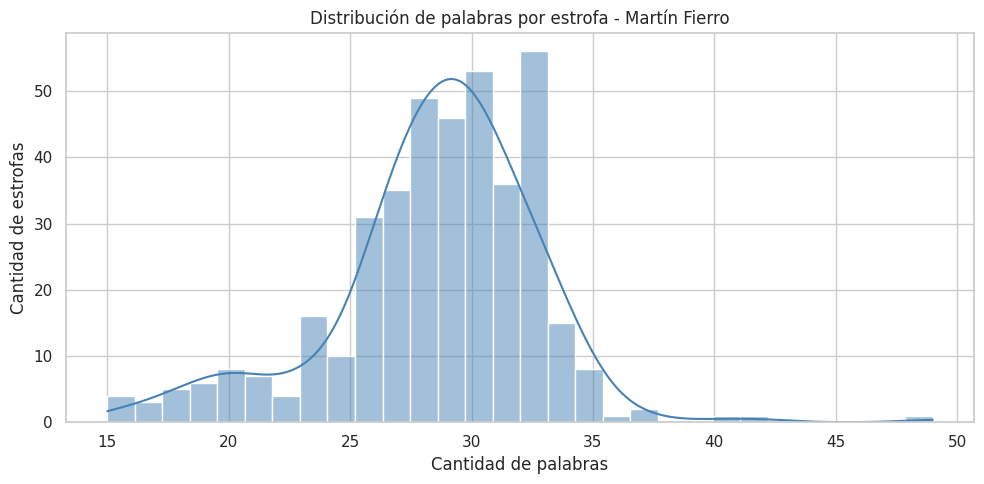

In [ ]:
# Configuración de gráficos
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="num_palabras",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Distribución de palabras por estrofa - Martín Fierro")
plt.xlabel("Cantidad de palabras")
plt.ylabel("Cantidad de estrofas")
plt.tight_layout()
plt.show()

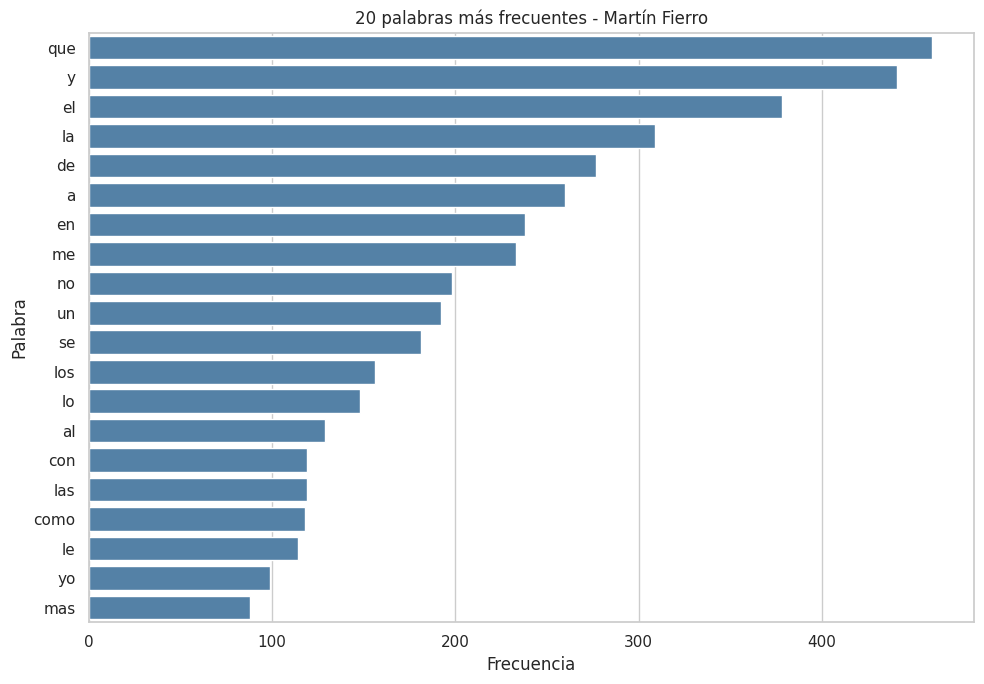

In [ ]:
frecuencias_palabras = Counter(
    token
    for token in todos_los_tokens
    if token.isalpha()
)

top_palabras = pd.DataFrame(
    frecuencias_palabras.most_common(20),
    columns=["palabra", "frecuencia"]
).sort_values("frecuencia", ascending=False)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_palabras,
    x="frecuencia",
    y="palabra",
    color="steelblue"
)

plt.title("20 palabras más frecuentes - Martín Fierro")
plt.xlabel("Frecuencia")
plt.ylabel("Palabra")
plt.tight_layout()
plt.show()

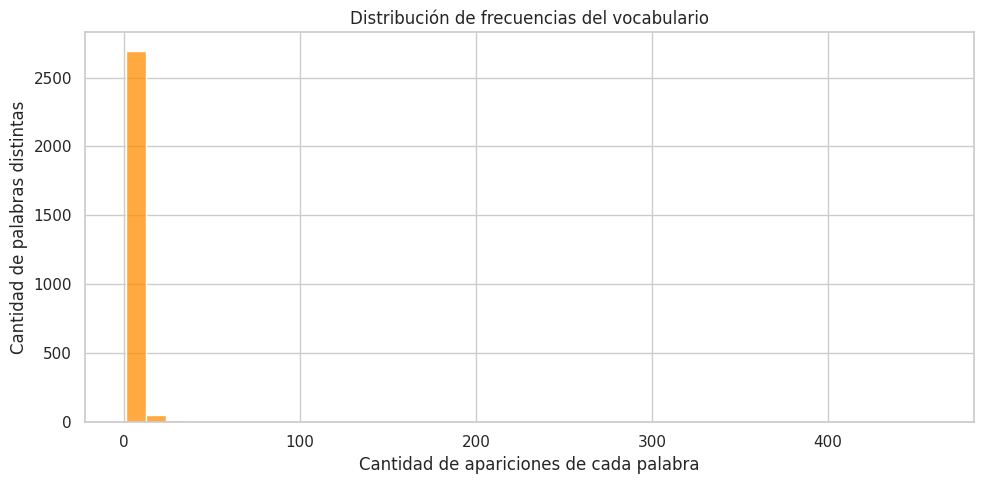

In [ ]:
frecuencias_df = pd.DataFrame({
    "palabra": list(frecuencias_palabras.keys()),
    "frecuencia": list(frecuencias_palabras.values())
})

plt.figure(figsize=(10, 5))

sns.histplot(
    data=frecuencias_df,
    x="frecuencia",
    bins=40,
    color="darkorange"
)

plt.title("Distribución de frecuencias del vocabulario")
plt.xlabel("Cantidad de apariciones de cada palabra")
plt.ylabel("Cantidad de palabras distintas")
plt.tight_layout()
plt.show()

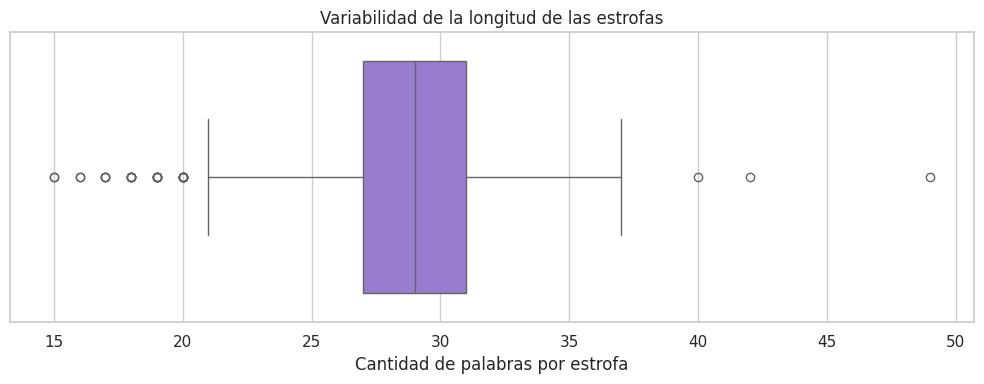

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="num_palabras",
    color="mediumpurple"
)

plt.title("Variabilidad de la longitud de las estrofas")
plt.xlabel("Cantidad de palabras por estrofa")
plt.tight_layout()
plt.show()

In [ ]:
one_hot = OneHot(tokenized_documents)

one_hot_matrix = one_hot.one_hot_matrix
one_hot_vocab = one_hot.one_hot_vocab

one_hot_to_index = one_hot.map_vocab_to_index()

print(f"\nDimensiones de la matriz One-Hot: {one_hot_matrix.shape}")

# 5. Mostrar algunos ejemplos
print("\nEjemplos de representaciones One-Hot:")
for i in range(min(5, len(one_hot_vocab))):
    word = one_hot_vocab[i]
    index = one_hot_to_index[word]

    print(f"\nToken: {word}")
    print(f"Índice en vocabulario: {index}")
    print(f"Vector One-Hot: {one_hot_matrix[i]}")


Dimensiones de la matriz One-Hot: (13293, 2806)

Ejemplos de representaciones One-Hot:

Token: aqui
Índice en vocabulario: 0
Vector One-Hot: [1 0 0 ... 0 0 0]

Token: me
Índice en vocabulario: 1
Vector One-Hot: [0 1 0 ... 0 0 0]

Token: pongo
Índice en vocabulario: 2
Vector One-Hot: [0 0 1 ... 0 0 0]

Token: a
Índice en vocabulario: 3
Vector One-Hot: [0 0 0 ... 0 0 0]

Token: cantar
Índice en vocabulario: 4
Vector One-Hot: [0 0 0 ... 0 0 0]


Dimensiones del DataFrame de Pandas completo: (13293, 2806)


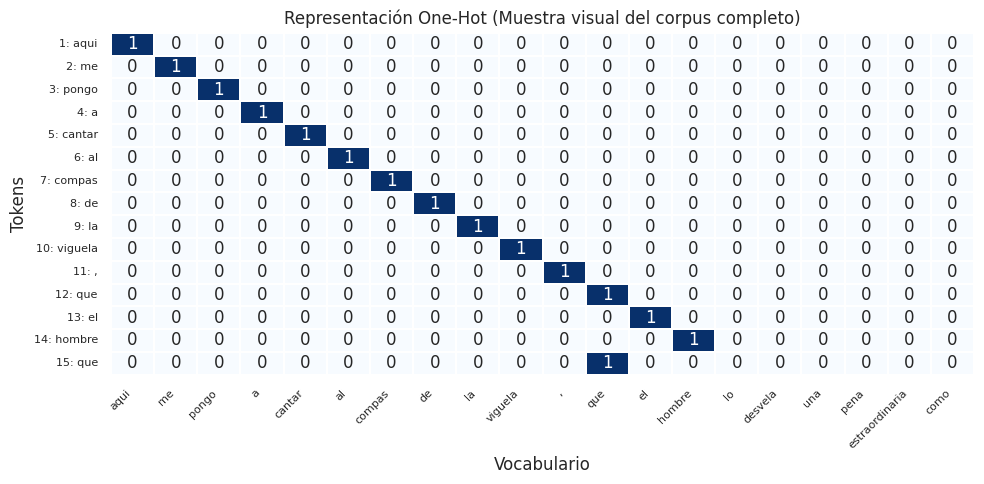

In [ ]:
# 1. Generamos el DataFrame completo con todos los datos
df_one_hot_full = one_hot.to_pandas_df()
print(f"Dimensiones del DataFrame de Pandas completo: {df_one_hot_full.shape}")

# 2. Limitamos únicamente la visualización recortando con iloc
n_tokens = 15
n_vocab = 20
df_one_hot_sample = df_one_hot_full.iloc[:n_tokens, :n_vocab]

plt.figure(figsize=(10, 5))

sns.heatmap(
    df_one_hot_sample,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    linewidths=0.3
)

plt.title('Representación One-Hot (Muestra visual del corpus completo)')
plt.xlabel('Vocabulario')
plt.ylabel('Tokens')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

## 📐 El Problema de la Ortogonalidad en One-Hot Encoding

En un espacio vectorial ideal para procesamiento de lenguaje natural, las palabras con significados o contextos similares (como *"pido"* y *"vengan"*) deberían estar "cerca" geométricamente.

Sin embargo, en la codificación **One-Hot**, cada palabra es tratada como una dimensión matemática totalmente independiente. Para comprobar esto matemáticamente, utilizaremos la **Similitud del Coseno**, definida como:

$$\text{Similitud Coseno}(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \|\mathbf{v}\|}$$

Si dos vectores son ortogonales (perpendiculares a 90°), su producto punto $\mathbf{u} \cdot \mathbf{v}$ es $0$, por lo que su similitud es $0$.

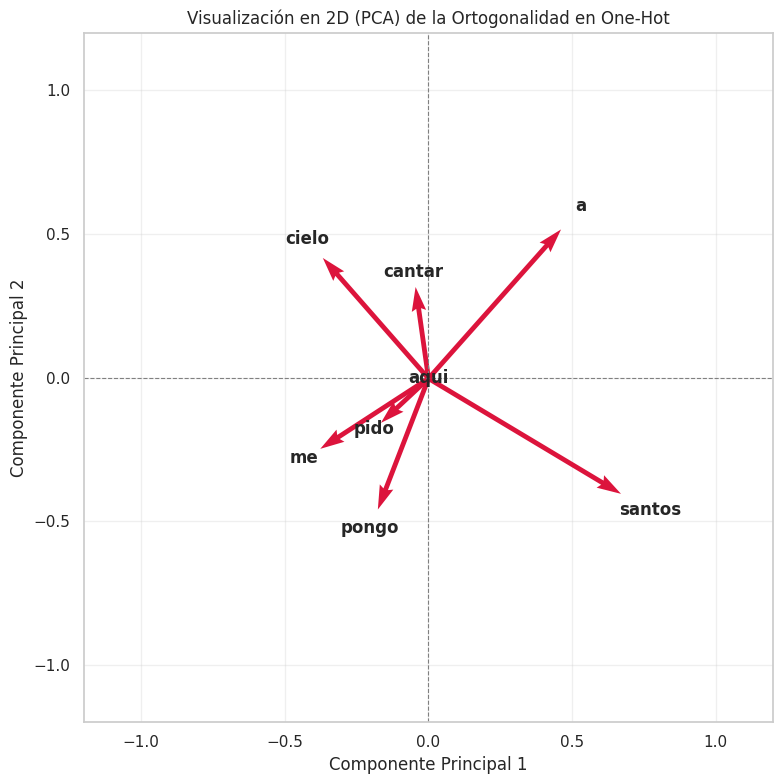

In [ ]:
# Definir un conjunto de palabras interesantes de nuestro vocabulario
palabras_prueba = ["aqui", "me", "pongo", "a", "cantar", "pido", "santos", "cielo"]

# Obtener los vectores One-Hot de estas palabras del encoder
vectores_prueba = []
for p in palabras_prueba:
    idx_p = one_hot_to_index[p]
    vec = np.zeros(len(one_hot_vocab))
    vec[idx_p] = 1
    vectores_prueba.append(vec)

vectores_prueba = np.array(vectores_prueba)

# Reducir la dimensionalidad a 2D usando PCA para visualizar la ortogonalidad
pca = PCA(n_components=2)
vectores_2d = pca.fit_transform(vectores_prueba)

# Graficar los vectores en un plano 2D como flechas saliendo del origen (0,0)
plt.figure(figsize=(8, 8))
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)

for i, palabra in enumerate(palabras_prueba):
    x, y = vectores_2d[i, 0], vectores_2d[i, 1]
    # Graficar la flecha
    plt.quiver(0, 0, x, y, angles='xy', scale_units='xy', scale=1, color='crimson', width=0.007)
    # Etiqueta de la palabra un poco desplazada para que sea legible
    plt.text(x * 1.15, y * 1.15, palabra, fontsize=12, fontweight='bold', ha='center', va='center')

plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.grid(True, alpha=0.3)
plt.title("Visualización en 2D (PCA) de la Ortogonalidad en One-Hot")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.show()

### Material Complementario

- [One Hot Encoding explained for NLP | Deep learning | NLP](https://www.youtube.com/watch?v=KtaouJNEu28)
- [Quick explanation: One-hot encoding](https://www.youtube.com/watch?v=G2iVj7WKDFk)